<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap10/10_1_1D_Convolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 10.1: 1D Convolution**

This notebook investigates 1D convolutional layers.

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and make predictions about what is going to happen or write code to complete the functions.

Contact me at udlbookmail@gmail.com if you find any mistakes or have any suggestions.


NOTE!!

If you have the first edition of the printed book, it mistakenly refers to a convolutional filter with no spaces between the elements (i.e. a normal filter without dilation) as having dilation zero.  Actually, the convention is (weirdly) that this has dilation one.  And when there is one space between the elements, this is dilation two.   This notebook reflects the correct convention and so will be out of sync with the printed book.  If this is confusing, check the [errata](https://github.com/udlbook/udlbook/blob/main/UDL_Errata.pdf) document.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Define a signal that we can apply convolution to
x = [5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1]

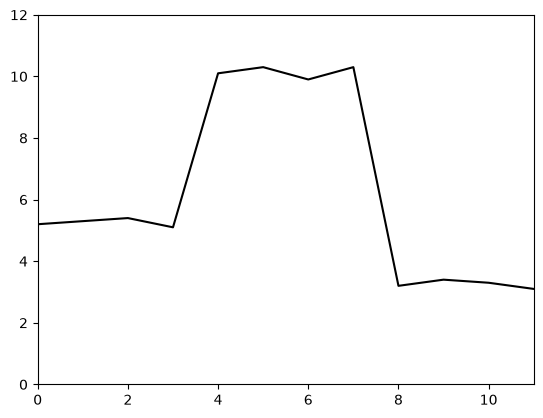

In [18]:
# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
plt.show()

In [19]:
# Now let's define a zero-padded convolution operation
# with a convolution kernel size of 3, a stride of 1, and a dilation of 1
# as in figure 10.2a-c.  Write it yourself, don't call a library routine!
# Don't forget that Python arrays are indexed from zero, not from 1 as in the book figures
def conv_3_1_1_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    # TODO -- write this function
    # replace this line
    x_out = np.zeros_like(x_in)
    n = len(x_in)
    
    # Rellenamos con un 0 al inicio y un 0 al final (zero padding)
    x_pad = [0] + list(x_in) + [0]

    # Multiplicamos los 3 valores correspondientes por sus pesos
    for i in range(n):
        x_out[i] = omega[0] * x_pad[i] + omega[1] * x_pad[i+1] + omega[2] * x_pad[i+2]
    return x_out


    return x_out

Now let's see what kind of things convolution can do
First, it can average nearby values, smoothing the function:

Sum of output is 71.1, should be 71.1


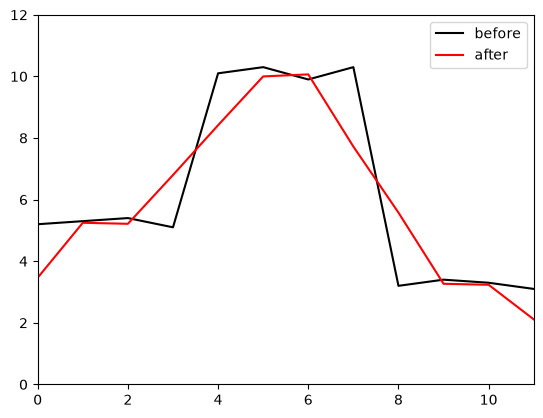

In [20]:

omega = [0.33,0.33,0.33]
h = conv_3_1_1_zp(x, omega)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h):3.3}, should be 71.1")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

Notice how the red function is a smoothed version of the black one as it has averaged adjacent values.  The first and last outputs are considerably lower than the original curve though.  Make sure that you understand why!<br><br>

With different weights, the convolution can be used to find sharp changes in the function:

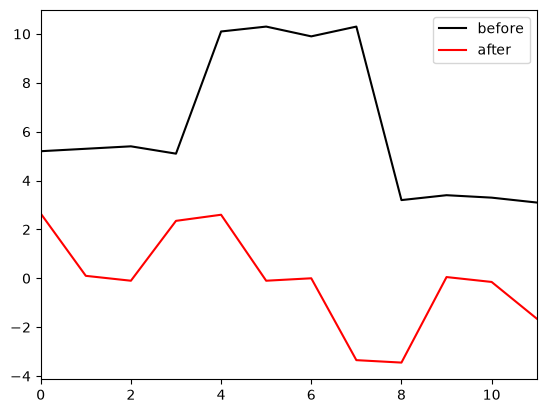

In [21]:

omega = [-0.5,0,0.5]
h2 = conv_3_1_1_zp(x, omega)

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h2, 'r-',label='after')
ax.set_xlim(0,11)
# ax.set_ylim(0, 12)
ax.legend()
plt.show()

Notice that the convolution has a peak where the original function went up and trough where it went down.  It is roughly zero where the function is locally flat.  This convolution approximates a derivative. <br> <br>

Now let's define the convolutions from figure 10.3.  

In [22]:
# Now let's define a zero-padded convolution operation
# with a convolution kernel size of 3, a stride of 2, and a dilation of 1
# as in figure 10.3a-b.  Write it yourself, don't call a library routine!
def conv_3_2_1_zp(x_in, omega):
    x_out = np.zeros(int(np.ceil(len(x_in)/2)))
    # TODO -- write this function
    # replace this line

    # Rellenamos con un 0 a cada extremo
    x_pad = [0] + list(x_in) + [0]

    # Con stride 2 avanzamos de dos en dos (pos = 2 * i)
    for i in range(len(x_out)):
        pos = 2 * i
        x_out[i] = omega[0] * x_pad[pos] + omega[1] * x_pad[pos+1] + omega[2] * x_pad[pos+2]

    return x_out



    return x_out

In [23]:
omega = [0.33,0.33,0.33]
h3 = conv_3_2_1_zp(x, omega)

# If you have done this right, the output length should be six and it should
# contain every other value from the original convolution with stride 1
print(h)
print(h3)

[ 3.465  5.247  5.214  6.798  8.415  9.999 10.065  7.722  5.577  3.267
  3.234  2.112]
[ 3.465  5.214  8.415 10.065  5.577  3.234]


In [24]:
# Now let's define a zero-padded convolution operation
# with a convolution kernel size of 5, a stride of 1, and a dilation of 1
# as in figure 10.3c.  Write it yourself, don't call a library routine!
def conv_5_1_1_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    # TODO -- write this function
    # replace this line
    n = len(x_in)

    # Para kernel de tamaño 5 necesitamos 2 ceros a cada lado
    x_pad = [0, 0] + list(x_in) + [0, 0]
    
    # Multiplicamos los 5 vecinos por los 5 pesos de omega
    for i in range(n):
        x_out[i] = (omega[0] * x_pad[i] +
                   omega[1] * x_pad[i+1] +
                   omega[2] * x_pad[i+2] +
                   omega[3] * x_pad[i+3] +
                   omega[4] * x_pad[i+4])
    return x_out



    return x_out

Sum of output is 69.6, should be 69.6


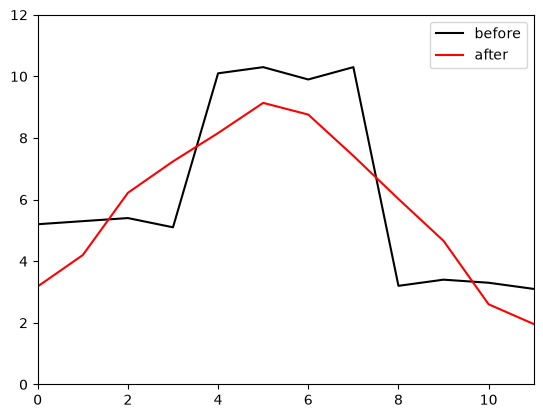

In [25]:

omega2 = [0.2, 0.2, 0.2, 0.2, 0.2]
h4 = conv_5_1_1_zp(x, omega2)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h4):3.3}, should be 69.6")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h4, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

In [26]:
# Finally let's define a zero-padded convolution operation
# with a convolution kernel size of 3, a stride of 1, and a dilation of 2
# as in figure 10.3d.  Write it yourself, don't call a library routine!
# Don't forget that Python arrays are indexed from zero, not from 1 as in the book figures
def conv_3_1_2_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    # TODO -- write this function
    # replace this line
    n = len(x_in)

    # Rellenamos con 2 ceros a cada lado
    x_pad = [0, 0] + list(x_in) + [0, 0]
    
    # Dilation 2: se evalúan las posiciones separadas por 2 pasos
    for i in range(n):
        x_out[i] = omega[0] * x_pad[i] + omega[1] * x_pad[i+2] + omega[2] * x_pad[i+4]
    return x_out

Sum of output is 68.3, should be 68.3


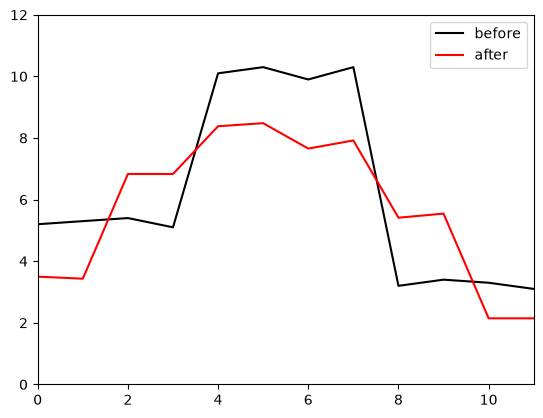

In [27]:
omega = [0.33,0.33,0.33]
h5 = conv_3_1_2_zp(x, omega)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h5):3.3}, should be 68.3")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h5, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

Finally, let's investigate representing convolutions as full matrices, and show we get the same answer.

In [28]:
# Compute matrix in figure 10.4 d
def get_conv_mat_3_1_1_zp(n_out, omega):
  omega_mat = np.zeros((n_out,n_out))
  # TODO Fill in this matrix
  # Replace this line:
  # Llenamos cada fila con los pesos en las posiciones vecinas
  for i in range(n_out):
      if i - 1 >= 0:
          omega_mat[i, i - 1] = omega[0]   # Vecino izquierdo
      omega_mat[i, i] = omega[1]           # Centro (diagonal)
      if i + 1 < n_out:
          omega_mat[i, i + 1] = omega[2]   # Vecino derecho
  return omega_mat


In [29]:
# Run original convolution
omega = np.array([-1.0,0.5,-0.2])
h6 = conv_3_1_1_zp(x, omega)
print(h6)

# If you have done this right, you should get the same answer
omega_mat = get_conv_mat_3_1_1_zp(len(x), omega)
h7 = np.matmul(omega_mat, x)
print(h7)


[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]
[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]


TODO:  What do you expect to happen if we apply the last convolution twice?  Can this be represented as a single convolution?  If so, then what is it?

Si aplicamos la convolución dos veces seguidas, el efecto que produce el filtro sobre la señal se intensifica; por ejemplo, si el objetivo era suavizar la curva, el resultado quedará todavía más suave. Además, el área de la señal que "ve" cada punto de salida se hace más amplia. En la primera pasada cada valor combina 3 números vecinos, pero al repetir la operación sobre esos nuevos resultados, cada valor final pasa a depender de una ventana de 5 elementos de la señal original.

Esto sí se puede representar como una única convolución directa, ya que solo estamos realizando sumas y multiplicaciones normales sin ninguna función no lineal de por medio. Encadenar dos capas convolucionales consecutivas con filtros de tamaño 3 produce exactamente el mismo resultado matemático que aplicar un solo filtro más amplio de tamaño 5 en un único paso.

Este nuevo filtro de tamaño 5 se calcula combinando el filtro original consigo mismo a través de sus multiplicaciones cruzadas. Al evaluar la segunda pasada sobre los resultados de la primera ($z_i = \omega_0 h_{i-1} + \omega_1 h_i + \omega_2 h_{i+1}$) y sustituir cada $h$ en función de la entrada original $x$, obtenemos:

$$z_i = \omega_0(\omega_0 x_{i-2} + \omega_1 x_{i-1} + \omega_2 x_i) + \omega_1(\omega_0 x_{i-1} + \omega_1 x_i + \omega_2 x_{i+1}) + \omega_2(\omega_0 x_i + \omega_1 x_{i+1} + \omega_2 x_{i+2})$$

Al agrupar los términos de cada posición de $x$, vemos que para un filtro original $[\omega_0, \omega_1, \omega_2]$, el filtro único resultante tiene como pesos $[\omega_0^2, \; 2\omega_0\omega_1, \; \omega_1^2 + 2\omega_0\omega_2, \; 2\omega_1\omega_2, \; \omega_2^2]$, lo que para los números del ejercicio equivale al filtro $[1.0, -1.0, 0.65, -0.2, 0.04]$.


### Resumen de lo visto

En este cuaderno aprendimos qué es y cómo se calcula una convolución desde cero. Vimos que no es más que una ventanita que se va moviendo a lo largo de una lista de números, multiplicando a los vecinos cercanos por unos pocos pesos y sumándolos. Según los números que pongamos en esa ventanita, podemos cambiar la señal a nuestro gusto: si usamos números iguales logramos que la curva quede más suave y pareja, pero si combinamos números positivos y negativos logramos resaltar en qué partes la curva sube o baja de golpe.

También entendimos para qué sirven sus ajustes básicos. Rellenar con ceros a los lados nos ayuda a que el resultado mantenga el mismo tamaño que la lista original, aunque haga que los extremos caigan un poco hacia abajo. Avanzar dando saltos de dos en dos nos permite achicar los datos a la mitad de forma directa. Y dejar espacios vacíos dentro del filtro nos deja abarcar una zona más ancha sin necesidad de agregar números de más.

Finalmente, vimos que esta operación se puede ver como una multiplicación de matrices común y corriente, pero con la gran ventaja de que casi toda la tabla está llena de ceros y los mismos números se repiten todo el tiempo. Esto hace que el modelo gaste poquísima memoria, haga las cuentas mucho más rápido y pueda mirar un pedazo cada vez más grande de los datos al poner una capa detrás de otra.